# Decision model
A decision model can only choose between options, it can't extract text, so we
flatten every application/action pair into a single choice (e.g. `maps.navigate`).

In [1]:
import json
import time
from typing import cast

from dotenv import load_dotenv
from IPython.display import JSON, display
from typesafe_sdk import Choice, ChoiceAnswer, TypeSafeClient

from demo_helpers import VALID_APPLICATIONS
from demo_helpers import plot_probabilities

load_dotenv()

True

In [ ]:
transcript = "Hey Google, navigate to Ara."

In [3]:
def build_criteria(valid_applications: dict[str, dict]) -> dict[str, str]:
    """Flatten every application/action pair into one option, e.g. "maps.navigate"."""
    criteria = {}
    for app_name, app in valid_applications.items():
        for action_name in app["actions"]:
            criteria[f"{app_name}.{action_name}"] = (
                f"{app['description']}: {action_name.replace('_', ' ')}"
            )
    return criteria

## Input

In [11]:
questions = {
    "command": Choice(
        instructions="Which application and action does the user want?",
        criteria=build_criteria(VALID_APPLICATIONS),
    ),
}
questions

{'command': Choice(type='choice', instructions='Which application and action does the user want?', criteria={'maps.navigate': 'Navigation and location search: navigate', 'maps.search_nearby': 'Navigation and location search: search nearby', 'maps.show_traffic': 'Navigation and location search: show traffic', 'music.play': 'Music streaming and playback: play', 'music.pause': 'Music streaming and playback: pause', 'music.skip': 'Music streaming and playback: skip', 'music.set_volume': 'Music streaming and playback: set volume', 'messages.send_message': 'Send and read text messages: send message', 'messages.read_latest': 'Send and read text messages: read latest', 'calendar.create_event': 'Manage events and reminders: create event', 'calendar.list_events': 'Manage events and reminders: list events', 'calendar.set_reminder': 'Manage events and reminders: set reminder', 'weather.current_conditions': 'Weather forecasts and conditions: current conditions', 'weather.forecast': 'Weather forecas

## Model call

In [21]:
with TypeSafeClient(model="jev-latest") as client:
    start = time.perf_counter()
    response = client.system_one(state=transcript, questions=questions)
    print(f"Client call took {time.perf_counter() - start:.2f}s")

Client call took 0.31s


## Output

In [17]:
response

SystemOneResponse(model='jev-1.14.0', usage=Usage(input_tokens=578, output_tokens=146), answers={'command': ChoiceAnswer(type='choice', choice='music.play', confidence=1.0, probabilities={'maps.navigate': 0.0, 'maps.search_nearby': 0.0, 'maps.show_traffic': 0.0, 'music.play': 1.0, 'music.pause': 0.0, 'music.skip': 0.0, 'music.set_volume': 0.0, 'messages.send_message': 0.0, 'messages.read_latest': 0.0, 'calendar.create_event': 0.0, 'calendar.list_events': 0.0, 'calendar.set_reminder': 0.0, 'weather.current_conditions': 0.0, 'weather.forecast': 0.0})})

In [18]:
answer = cast(ChoiceAnswer, response.answers["command"])
print(answer.model_dump_json(indent=2))

{
  "type": "choice",
  "choice": "music.play",
  "confidence": 1.0,
  "probabilities": {
    "maps.navigate": 0.0,
    "maps.search_nearby": 0.0,
    "maps.show_traffic": 0.0,
    "music.play": 1.0,
    "music.pause": 0.0,
    "music.skip": 0.0,
    "music.set_volume": 0.0,
    "messages.send_message": 0.0,
    "messages.read_latest": 0.0,
    "calendar.create_event": 0.0,
    "calendar.list_events": 0.0,
    "calendar.set_reminder": 0.0,
    "weather.current_conditions": 0.0,
    "weather.forecast": 0.0
  }
}


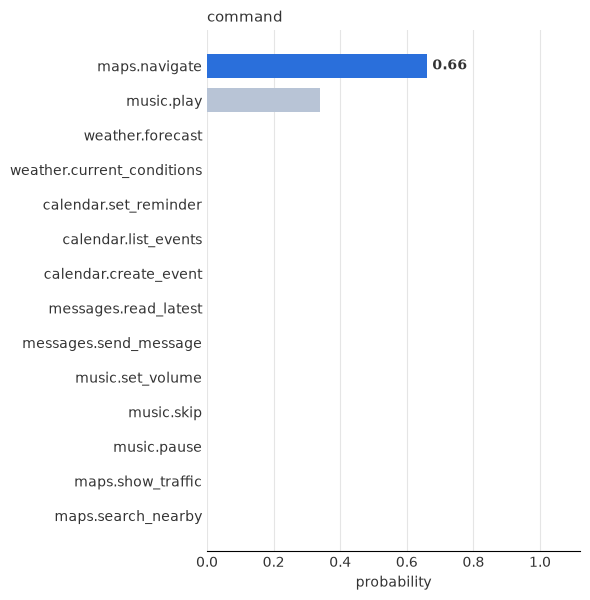

In [22]:
plot_probabilities(response.answers)